# Nhóm 3, Notebook_A (Sinh viên A): dữ liệu, EDA, làm sạch, SQL, hình RQ1

**Đề tài**: Phát hiện và nhận dạng drone qua RF (DroneRF)

**Khung SDG**: SDG 9 và SDG 16: an ninh hạ tầng trọng yếu, chống UAS; tiêu đề, keyword và abstract của bài dùng đúng cụm từ này.

**Vai trò**: Sinh viên A làm Bước 0 đến 3 và phần hình RQ1 của Bước 5, bàn giao `data/processed/feat.parquet` cùng `manifest.json` cho Sinh viên B (Notebook_B). Chạy tuần tự trong VS Code với extension Python và Jupyter, interpreter `.venv`. Mỗi bước có ô hướng dẫn *làm gì, vì sao, đọc thế nào* rồi đến ô code; mọi bảng lưu vào `report/` với tên `table_*.csv`, mọi hình `fig_*.png`.

**Quy tắc**: seed 42; không xoá dòng mà không ghi lý do; mọi prompt AI ghi vào Audit Log cá nhân; báo cáo slot 3 thứ Ba và thứ Sáu theo mẫu ở ô cuối.

## Vừa làm vừa hỏi AI và ghi Audit Log: cách làm nhẹ nhàng, không rối

**Tinh thần**: AI là bạn cùng làm, không phải người làm thay. Bạn được hỏi AI bất cứ lúc nào; điều duy nhất phải giữ là *kiểm tra một lần* trước khi dùng và *ghi lại 2 phút* nếu câu hỏi đó thay đổi việc bạn làm.

**Khi nào hỏi AI** (theo thứ tự):
1. Đọc ô hướng dẫn của bước đang làm (1 phút).
2. Thử tự làm 15 phút.
3. Bí quá 15 phút thì hỏi AI với mẫu: *"Tôi đang làm Bước X của dự án Y. Dữ liệu có cột A, B, C. Tôi muốn Z. Đây là code và lỗi: ... Hãy giải thích nguyên nhân và sửa, giữ nguyên tên biến."*
4. Chạy thử code AI đưa trên dữ liệu thật; so một con số bằng tay hoặc bằng cách thứ hai.
5. Nếu vẫn bí sau 30 phút, ghi lại lỗi và hỏi giảng viên ở kênh nhóm.

**Ghi Audit Log thế nào cho không áp lực**: chỉ ghi các prompt *đã thay đổi việc bạn làm* (thường 3 đến 5 prompt một tuần, 15 đến 20 cả kỳ). Mỗi dòng 5 ô, điền trong 2 phút ngay khi dùng, không để cuối tuần:

| Ngày, bước | Prompt (rút gọn) | AI trả lời gì (1 dòng) | Tôi kiểm tra hoặc sửa gì | Dùng vào đâu |
|---|---|---|---|---|
| 09/09, Bước 3 | viết truy vấn trung bình trượt 7 ngày theo trạm | đưa AVG OVER ROWS 6 PRECEDING | thiếu PARTITION BY site_num, thêm và thử 2 trạm | Q3 trong sql/queries.sql |

Cột thứ tư chính là *Human Delta* và là thứ hội đồng hỏi; ghi thật, kể cả khi AI đúng ("kiểm tra bằng 10 dòng tính tay, khớp"). Ba lần bạn phát hiện AI sai trong cả kỳ là đủ yêu cầu.

**Nhịp làm việc**: mỗi ngày 1,5 đến 2 giờ vào đúng bước của tuần, xong một ô thì commit; thứ Ba và thứ Sáu slot 1 báo cáo năm mục đúng tiến độ, dù kết quả chưa đẹp. Siêng và đúng nhịp quan trọng hơn giỏi: nhóm báo cáo đều 6 lần trong 3 tuần luôn có bài, nhóm im lặng đến tuần 3 thường không kịp.

## Bước 0: môi trường và cấu trúc thư mục




In [1]:
# Step 0: Import Libraries & Environment Configuration
import os
import json
import numpy as np
import pandas as pd
import duckdb

# Determine Project Root Directory (auto-detect if running inside 'notebooks' folder)
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    BASE_DIR = os.path.abspath(os.path.join(current_dir, ".."))
else:
    BASE_DIR = current_dir

RAW_DIR = os.path.join(BASE_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
REPORT_DIR = os.path.join(BASE_DIR, "report")

# Stage 1: RAW features, unnormalized, unlabelled drone/dtype/mode
STAGE1_PARQUET = os.path.join(PROCESSED_DIR, "dronerf_features.parquet")
STAGE1_CSV     = os.path.join(PROCESSED_DIR, "dronerf_features.csv")

# Stage 2: after spectral energy normalization + labelling -> handoff to Step 3 and Notebook_B
OUTPUT_FILE    = os.path.join(PROCESSED_DIR, "dronerf.parquet")
MANIFEST_FILE  = os.path.join(REPORT_DIR, "manifest.json")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print(f"Root workspace path      : {BASE_DIR}")
print(f" - Raw data directory    : {RAW_DIR}")
print(f" - Stage 1 cache (parquet): {STAGE1_PARQUET}")
print(f" - Stage 1 cache (csv)    : {STAGE1_CSV}")
print(f" - Final output (Buoc 2) : {OUTPUT_FILE}")
print(f" - Manifest file         : {MANIFEST_FILE}")

Root workspace path      : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D
 - Raw data directory    : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\raw
 - Stage 1 cache (parquet): d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf_features.parquet
 - Stage 1 cache (csv)    : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf_features.csv
 - Final output (Buoc 2) : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf.parquet
 - Manifest file         : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\manifest.json


## Vì sao sáu bước và mỗi bước giúp gì cho bài

| Bước | Mục đích | Lợi ích cho bài | Bằng chứng, câu hỏi |
|---|---|---|---|
| 1 Nạp, hiểu dữ liệu | biết quy mô, thời gian, đơn vị, mục tiêu | bảng mô tả dữ liệu, phạm vi hợp lệ | table_describe, profile; nền mọi RQ |
| 2 Làm sạch, ghép | dữ liệu tin được, có nguồn thứ hai | nhật ký làm sạch trả lời phản biện; đặc trưng ngoại sinh | cleaning_log, tỷ lệ khớp; RQ1, RQ2 |
| 3 SQL, EDA | trả lời câu hỏi mô tả bằng số có kiểm định; đặc trưng đúng thời điểm | bảng RQ1 có p-value; không rò rỉ; điểm SQL | table_q*, rq1a-c; RQ1 |
| 4 Chia dữ liệu | đánh giá công bằng | mốc naive cho biết cải thiện thật | table_features; RQ2 |
| 5 Trực quan hoá | thấy cấu trúc và bất thường; truyền đạt | hình có caption kết luận | fig_rq1_*; RQ1 |
| 6 Mô hình, RQ3 | so năm mô hình công bằng; đóng góp chính | bảng có độ lệch, tinh chỉnh có căn cứ, SHAP | table_rq2, rq3; RQ2, RQ3 |

**Vì sao phải chọn cột từ nhiều cột**: cột thừa làm mô hình học nhiễu, cột chứa giá trị tương lai làm kết quả đẹp giả, cột không có lúc vận hành làm mô hình vô dụng. Bốn bước giúp chọn đúng cột và khớp RQ: (1) tài liệu cơ quan cho biết ý nghĩa vật lý; (2) bảng thiếu và bảng tương quan trong EDA loại cột thiếu nhiều hoặc trùng; (3) SQL với LAG/LEAD tách quá khứ khỏi tương lai; (4) SHAP sau mô hình xác nhận cột thực sự đóng góp. Mỗi cột giữ lại phải nối về một RQ: cột mô tả cho RQ1, cột dự báo cho RQ2, cột nhóm hoặc điều kiện cho RQ3.

## Bước 1: hiểu bài toán và nạp dữ liệu

### 1.1. DEFINE FEATURE EXTRACTION FUNCTION



In [2]:
import glob
from scipy.stats import kurtosis
import os

def extract_rf_features(file_path, window_size=20000):
   
    filename = os.path.basename(file_path)
    base_name = os.path.splitext(filename)[0]

    # BUI code + frequency band from filename, e.g., '10000L_0.csv' -> code='10000', band='L'
    stem = base_name.split("_")[0]
    band = stem[-1]
    code = stem[:-1]

    try:
        raw_signal = pd.read_csv(file_path, header=None, engine="c").values.flatten()
    except Exception as e:
        print(f"Loi doc file {filename}: {e}")
        return []

    records = []
    num_samples = len(raw_signal)

    for win_idx, start_pos in enumerate(range(0, num_samples - window_size + 1, window_size)):
        segment = raw_signal[start_pos: start_pos + window_size]

        # --- Time-domain features ---
        rms_val = float(np.sqrt(np.mean(segment ** 2)))
        peak_val = float(np.abs(segment).max())
        kurt_val = float(kurtosis(segment, fisher=True, bias=False))

        # --- Frequency-domain features (FFT magnitude spectrum) ---
        fft_vals = np.abs(np.fft.rfft(segment))
        n_fft = len(fft_vals)
        freqs = np.arange(n_fft)

        spec_centroid = float((fft_vals * freqs).sum() / (fft_vals.sum() + 1e-12))
        spec_bw = float(fft_vals.std())
        spec_max = float(fft_vals.max())

        split_third = n_fft // 3
        spec_e_lo = float(np.sum(fft_vals[:split_third] ** 2))
        spec_e_mid = float(np.sum(fft_vals[split_third: 2 * split_third] ** 2))
        spec_e_hi = float(np.sum(fft_vals[2 * split_third:] ** 2))

        records.append({
            "code": code, "band": band, "seg": filename, "win": win_idx,
            "rms": rms_val, "peak": peak_val, "kurt": kurt_val,
            "spec_centroid": spec_centroid, "spec_bw": spec_bw, "spec_max": spec_max,
            "spec_e_lo": spec_e_lo, "spec_e_mid": spec_e_mid, "spec_e_hi": spec_e_hi,
        })

    return records

print("Feature extraction function defined successfully (9 features + metadata).")


Feature extraction function defined successfully (9 features + metadata).


### 1.2. BATCH PROCESSING RAW CSV FILES



In [3]:
import os
import glob
import pandas as pd

# PRIORITY: if Step 1 cache exists (dronerf_features.parquet or .csv), read directly,
# ABSOLUTELY DO NOT re-scan the 454 original files (3.75GB).
if os.path.exists(STAGE1_PARQUET):
    print(f"Found Step 1 cache (parquet): {STAGE1_PARQUET} -> reading directly, skipping ingest.")
    df_raw_features = pd.read_parquet(STAGE1_PARQUET)
elif os.path.exists(STAGE1_CSV):
    print(f"Found Step 1 cache (csv): {STAGE1_CSV} -> reading directly, skipping ingest.")
    df_raw_features = pd.read_csv(STAGE1_CSV)
    df_raw_features.to_parquet(STAGE1_PARQUET, index=False, compression="snappy")  # save a parquet copy for next time
else:
    print(f"Cache not found. Scanning directory: {RAW_DIR}")
    raw_files = sorted(glob.glob(os.path.join(RAW_DIR, "**", "*.csv"), recursive=True))
    print(f"Found {len(raw_files)} original CSV files. Starting feature extraction...")

    all_extracted_records = []
    for idx, file_path in enumerate(raw_files, start=1):
        all_extracted_records.extend(extract_rf_features(file_path))
        if idx % 50 == 0 or idx == len(raw_files):
            print(f" Progress: [{idx}/{len(raw_files)}] files processed...")

    df_raw_features = pd.DataFrame(all_extracted_records)
    df_raw_features.to_parquet(STAGE1_PARQUET, index=False, compression="snappy")
    df_raw_features.to_csv(STAGE1_CSV, index=False)
    print(f"Saved Step 1 cache to: {STAGE1_PARQUET}")

print(f"Total current windows (rows): {len(df_raw_features):,}")
df_raw_features.head()

Found Step 1 cache (parquet): d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf_features.parquet -> reading directly, skipping ingest.
Total current windows (rows): 226,546


,code,seg,win,band,rms,peak,kurt,spec_centroid,spec_bw,spec_max,spec_e_lo,spec_e_mid,spec_e_hi
0,10100,0,0,H,2.543708,43.0,5.571322,966.674809,179.630178,1185.864785,196006.620465,179786.089262,319087.719069
1,10100,0,1,H,2.483022,10.0,0.014666,972.440713,175.931400,1318.000000,182069.324248,172864.820997,308571.395844
2,10100,0,2,H,2.490673,10.0,-0.042017,968.894017,175.808350,2459.000000,182925.752786,176293.520206,312857.206621
3,10100,0,3,H,2.551117,12.0,0.075884,983.121218,183.418268,2238.000000,188120.514176,176061.395297,330022.292917
4,10100,0,4,H,2.781223,15.0,0.158857,1007.212219,202.094352,1213.232795,195963.992827,214270.575355,383575.932504


### 1.3: CONSTRUCT MASTER DATAFRAME


In [4]:
# 1.3: Quick check of Step 1 results (DO NOT recreate df_raw_features here to avoid overwriting Cell 1.2 results)
assert "df_raw_features" in dir(), "df_raw_features not found - please re-run Cell 1.2 first."
assert len(df_raw_features) > 0, "df_raw_features is empty - check RAW_DIR or Step 1 cache file."

print(f"Number of rows     : {len(df_raw_features):,}")
print(f"Number of columns  : {df_raw_features.shape[1]} -> {list(df_raw_features.columns)}")
print(f"Unique code count  : {df_raw_features['code'].nunique()}")
df_raw_features.head()

Number of rows     : 226,546
Number of columns  : 13 -> ['code', 'seg', 'win', 'band', 'rms', 'peak', 'kurt', 'spec_centroid', 'spec_bw', 'spec_max', 'spec_e_lo', 'spec_e_mid', 'spec_e_hi']
Unique code count  : 10


,code,seg,win,band,rms,peak,kurt,spec_centroid,spec_bw,spec_max,spec_e_lo,spec_e_mid,spec_e_hi
0,10100,0,0,H,2.543708,43.0,5.571322,966.674809,179.630178,1185.864785,196006.620465,179786.089262,319087.719069
1,10100,0,1,H,2.483022,10.0,0.014666,972.440713,175.931400,1318.000000,182069.324248,172864.820997,308571.395844
2,10100,0,2,H,2.490673,10.0,-0.042017,968.894017,175.808350,2459.000000,182925.752786,176293.520206,312857.206621
3,10100,0,3,H,2.551117,12.0,0.075884,983.121218,183.418268,2238.000000,188120.514176,176061.395297,330022.292917
4,10100,0,4,H,2.781223,15.0,0.158857,1007.212219,202.094352,1213.232795,195963.992827,214270.575355,383575.932504


## Bước 2: hiểu dữ liệu và làm sạch, ghép nguồn thứ hai



### 2.1: ENERGY NORMALIZATION & MISSING VALUES HANDLING


In [5]:
# 2.1: Normalize spectral energy to [0,1] scale + assign drone/dtype/mode labels from 'code'
df_clean = df_raw_features.copy()

required_cols = ["code", "band", "rms", "spec_e_lo", "spec_e_mid", "spec_e_hi"]
missing = [c for c in required_cols if c not in df_clean.columns]
assert not missing, f"Missing required columns: {missing} - re-check extract_rf_features function (Cell 1.1)."

total_energy = df_clean["spec_e_lo"] + df_clean["spec_e_mid"] + df_clean["spec_e_hi"]
df_clean["spec_e_lo_norm"] = np.where(total_energy > 0, df_clean["spec_e_lo"] / total_energy, 0.0)
df_clean["spec_e_mid_norm"] = np.where(total_energy > 0, df_clean["spec_e_mid"] / total_energy, 0.0)
df_clean["spec_e_hi_norm"] = np.where(total_energy > 0, df_clean["spec_e_hi"] / total_energy, 0.0)

# --- Assign labels from BUI code (first 5 characters of 'code'): first digit = 1 means drone present, 0 means background ---
code_str = df_clean["code"].astype(str).str.zfill(5)
# IMPORTANT: overwrite the 'code' column itself with the normalized version (string, zfill 5),
# because the original might be int64 (when re-reading from CSV cache) or missing leading zeros (e.g. "0" instead of "00000").
# If not forced here, Notebook_B/C/D will throw errors when concatenating strings (code + "_" + seg) due to data type mismatch.
df_clean["code"] = code_str
df_clean["drone"] = (code_str.str[0] == "1").astype(int)
df_clean["dtype"] = code_str.str[:3].map({
    "000": "none", "100": "Bebop", "101": "AR", "110": "Phantom"
}).fillna("other")
df_clean["mode"] = code_str.str[3:5]

df_clean = df_clean.fillna(0.0)

print("Spectral energy normalization and drone/dtype/mode label assignment completed successfully!")
print(df_clean[["code", "band", "drone", "dtype", "mode"]].drop_duplicates().head(10))

Spectral energy normalization and drone/dtype/mode label assignment completed successfully!
         code band  drone dtype mode
0       10100    H      1    AR   00
10479   10100    L      1    AR   00
20958   10101    H      1    AR   01
31437   10101    L      1    AR   01
41916   10110    H      1    AR   10
52395   10110    L      1    AR   10
62874   10111    H      1    AR   11
71856   10111    L      1    AR   11
80838   00000    H      0  none   00
101297  00000    L      0  none   00


### 2.2: SANITY CHECK & DATA AUDIT


In [6]:
# 2.2: Sanity Check & Data Audit
sample_sum = (
    df_clean["spec_e_lo_norm"] +
    df_clean["spec_e_mid_norm"] +
    df_clean["spec_e_hi_norm"]
).round(5)
assert (sample_sum.isin([0.0, 1.0])).all(), "Spectral energy normalization is incorrect!"
assert df_clean["drone"].notna().all(), "The 'drone' label column contains missing values!"

print("Data summary after cleaning:")
print(f" - Total rows         : {len(df_clean):,}")
print(f" - Number of columns  : {df_clean.shape[1]} -> {list(df_clean.columns)}")
print(f" - Unique code count  : {df_clean['code'].nunique()}")
print(f" - Frequency bands    : {df_clean['band'].unique().tolist()}")
print(" - Drone/background ratio:")
print(df_clean["drone"].value_counts(normalize=True).round(3))
print(" - Drone type distribution:")
print(df_clean["dtype"].value_counts())

df_clean.head()

Data summary after cleaning:
 - Total rows         : 226,546
 - Number of columns  : 19 -> ['code', 'seg', 'win', 'band', 'rms', 'peak', 'kurt', 'spec_centroid', 'spec_bw', 'spec_max', 'spec_e_lo', 'spec_e_mid', 'spec_e_hi', 'spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm', 'drone', 'dtype', 'mode']
 - Unique code count  : 10
 - Frequency bands    : ['H', 'L']
 - Drone/background ratio:
drone
1    0.819
0    0.181
Name: proportion, dtype: float64
 - Drone type distribution:
dtype
Bebop      83832
AR         80838
none       40918
Phantom    20958
Name: count, dtype: int64


,code,seg,win,band,rms,peak,kurt,spec_centroid,spec_bw,spec_max,spec_e_lo,spec_e_mid,spec_e_hi,spec_e_lo_norm,spec_e_mid_norm,spec_e_hi_norm,drone,dtype,mode
0,10100,0,0,H,2.543708,43.0,5.571322,966.674809,179.630178,1185.864785,196006.620465,179786.089262,319087.719069,0.282072,0.258730,0.459198,1,AR,00
1,10100,0,1,H,2.483022,10.0,0.014666,972.440713,175.931400,1318.000000,182069.324248,172864.820997,308571.395844,0.274405,0.260533,0.465062,1,AR,00
2,10100,0,2,H,2.490673,10.0,-0.042017,968.894017,175.808350,2459.000000,182925.752786,176293.520206,312857.206621,0.272180,0.262312,0.465508,1,AR,00
3,10100,0,3,H,2.551117,12.0,0.075884,983.121218,183.418268,2238.000000,188120.514176,176061.395297,330022.292917,0.270987,0.253616,0.475397,1,AR,00
4,10100,0,4,H,2.781223,15.0,0.158857,1007.212219,202.094352,1213.232795,195963.992827,214270.575355,383575.932504,0.246865,0.269927,0.483208,1,AR,00


### 2.3: EXPORT TO STANDARDIZED PARQUET FILE



In [7]:
# 2.3: Export normalized + labelled feature table to official parquet file (handoff to Step 3 and Notebook_B)
df_clean.to_parquet(OUTPUT_FILE, index=False, compression="snappy")

file_size_mb = os.path.getsize(OUTPUT_FILE) / (1024 * 1024)
print("File exported successfully!")
print(f" - Path     : {OUTPUT_FILE}")
print(f" - Size     : {file_size_mb:.2f} MB")
print(f" - Rows     : {len(df_clean):,}")

File exported successfully!
 - Path     : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf.parquet
 - Size     : 20.73 MB
 - Rows     : 226,546


### 2.4: EDA - STATISTICAL SUMMARY & DISTRIBUTION ANALYSIS

Cell 2.4: Descriptive Statistics & Missing Values Check

In [8]:
# Compute summary statistics for numeric features
print("📊 Descriptive Statistics for Key Features:")
display(df_clean[['rms', 'spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm']].describe().T)

# Verify class distribution across RF bands and codes
print("\n🏷️ Sample Count by Band:")
display(df_clean['band'].value_counts().to_frame())

print("\n🏷️ Sample Count per Drone Code (Top 10):")
display(df_clean['code'].value_counts().head(10).to_frame())

📊 Descriptive Statistics for Key Features:


,count,mean,std,min,25%,50%,75%,max
rms,226546.0,73.063560,317.791821,2.240458,2.380998,2.429928,2.536442,4520.049510
spec_e_lo_norm,226546.0,0.261977,0.057054,0.006960,0.270565,0.275845,0.280238,0.587371
spec_e_mid_norm,226546.0,0.252523,0.050128,0.008494,0.259069,0.263790,0.268003,0.490130
spec_e_hi_norm,226546.0,0.485500,0.105634,0.140342,0.454861,0.459596,0.465325,0.984351



🏷️ Sample Count by Band:


,count
band,
H,113273
L,113273



🏷️ Sample Count per Drone Code (Top 10):


,count
code,
00000,40918
10100,20958
10101,20958
10110,20958
10000,20958
10001,20958
10011,20958
10010,20958
11000,20958


### 2.5: EDA - FEATURE CORRELATION ANALYSIS

Cell 2.5: Correlation Matrix among Spectrum Energies and RMS

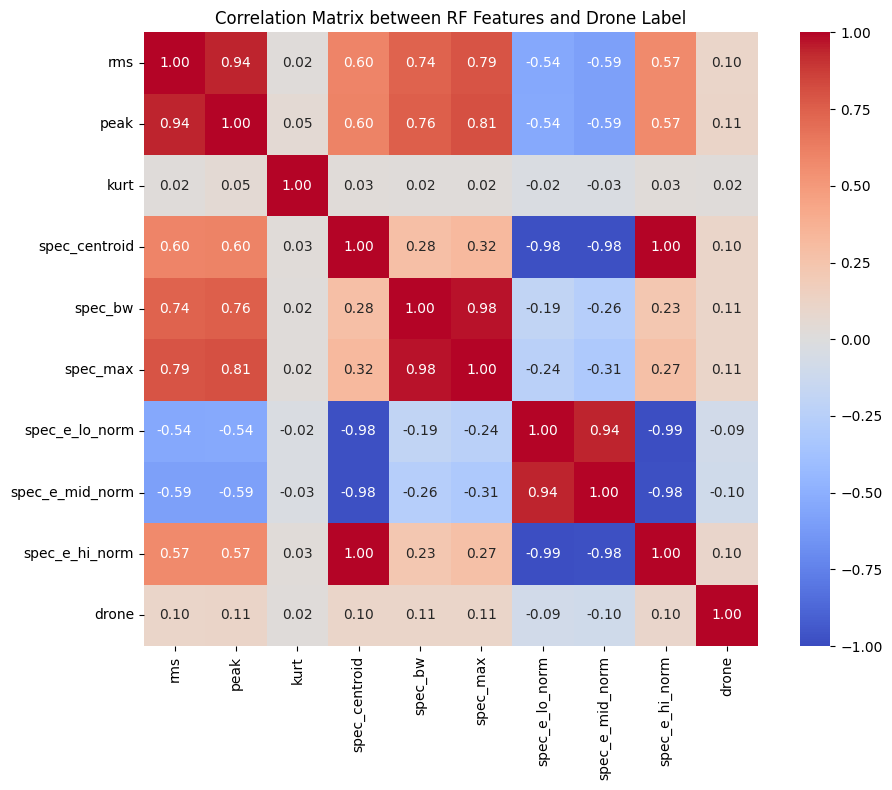

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical feature columns to compute correlation matrix
corr_cols = ['rms', 'peak', 'kurt', 'spec_centroid', 'spec_bw', 'spec_max', 
             'spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm', 'drone']
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix between RF Features and Drone Label", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "fig_correlation_matrix.png"), dpi=300)
plt.show()

### 2.6: EDA - SPECTRAL ENERGY DISTRIBUTION BY RF BAND
Cell 2.6: Compare Spectral Features across 'L' and 'H' Bands

⚡ Average Normalized Spectral Energy by Band:


,spec_e_lo_norm,spec_e_mid_norm,spec_e_hi_norm,rms
band,,,,
H,0.272521,0.263695,0.463784,5.180406
L,0.251432,0.241352,0.507216,140.946715


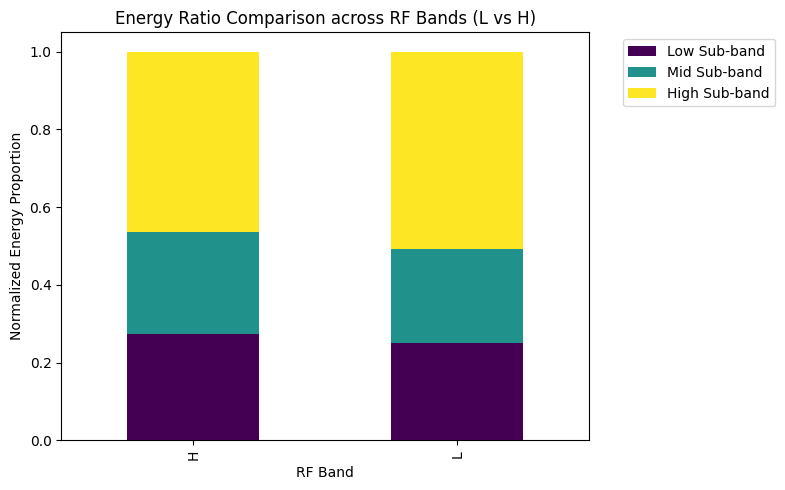

In [10]:
# Compare average spectral energies across different bands (Low vs High band)
band_summary = df_clean.groupby('band')[['spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm', 'rms']].mean()

print("⚡ Average Normalized Spectral Energy by Band:")
display(band_summary)

# Visualize Energy Distribution across Bands
band_summary[['spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm']].plot(
    kind='bar', 
    stacked=True, 
    figsize=(8, 5), 
    colormap='viridis'
)
plt.title("Energy Ratio Comparison across RF Bands (L vs H)")
plt.ylabel("Normalized Energy Proportion")
plt.xlabel("RF Band")
plt.legend(["Low Sub-band", "Mid Sub-band", "High Sub-band"], bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Bước 3: phân tích bằng SQL, trả lời RQ1 và tạo đặc trưng



### 3.1: DUCKDB INITIALIZATION & DATA LOADING
Cell 3.1: Connect to DuckDB and Register Parquet View

In [11]:
# Initialize DuckDB in-memory database connection
con = duckdb.connect(database=':memory:')

# Register the master parquet file as a DuckDB view
con.execute(f"""
    CREATE OR REPLACE VIEW rf_features AS 
    SELECT * FROM read_parquet('{OUTPUT_FILE}')
""")

# Verify record count inside DuckDB
db_count = con.execute("SELECT COUNT(*) FROM rf_features").fetchone()[0]
print(f"✅ Successfully loaded DuckDB View 'rf_features' with {db_count:,} records.")

✅ Successfully loaded DuckDB View 'rf_features' with 226,546 records.


### 3.2: RQ1 & RQ2 - AGGREGATION ANALYTICS BY BAND & CODE

Cell 3.2: Execute Q1 & Q2 Queries (Band & Code Summaries)

📊 Q1: Band-level Feature Aggregations:


,band,total_windows,avg_rms,std_rms,avg_spec_e_lo,avg_spec_e_mid,avg_spec_e_hi
0,H,113273,5.180406,12.460854,0.2725,0.2637,0.4638
1,L,113273,140.946715,438.876492,0.2514,0.2414,0.5072



📊 Q2: Top 10 Code/Band Aggregations:


,code,band,window_count,avg_rms,avg_spec_e_lo
0,00000,H,20459,3.113715,0.2735
1,00000,L,20459,2.977839,0.2723
2,10110,L,10479,34.357577,0.2477
3,10101,L,10479,28.939304,0.2512
4,10010,H,10479,3.191499,0.2739
5,10011,H,10479,3.195466,0.2742
6,10000,L,10479,367.508245,0.2287
7,10100,H,10479,3.026827,0.2754
8,11000,L,10479,172.906211,0.3247
9,10100,L,10479,91.038229,0.2341


C:\Users\PV\AppData\Local\Temp\ipykernel_16464\2116288797.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_q1, x='band', y='total_windows', ax=axes[0], palette='Blues_d')


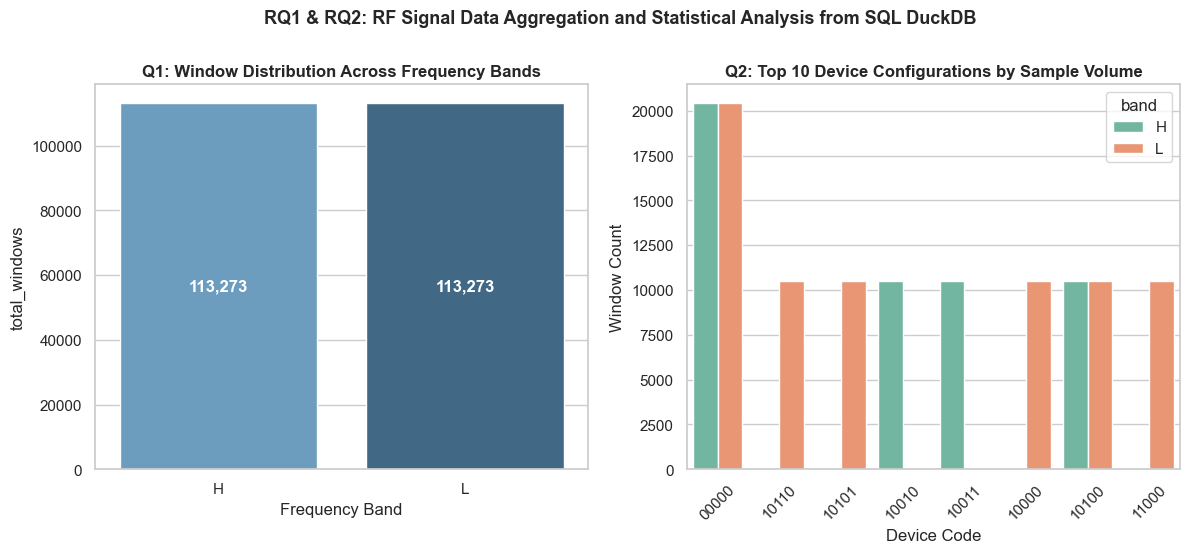


=== EXPORTED FILES TO ROOT DIRECTORY STRUCTURE SUCCESSFULLY ===
[+] CSV Report : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\table_q1_summary.csv
[+] Figure File: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\fig_rq1_sql.png


In [12]:
# Q1: Band-level Aggregation Summary
query_q1 = """
SELECT 
    band,
    COUNT(*) AS total_windows,
    ROUND(AVG(rms), 6) AS avg_rms,
    ROUND(STDDEV(rms), 6) AS std_rms,
    ROUND(AVG(spec_e_lo_norm), 4) AS avg_spec_e_lo,
    ROUND(AVG(spec_e_mid_norm), 4) AS avg_spec_e_mid,
    ROUND(AVG(spec_e_hi_norm), 4) AS avg_spec_e_hi
FROM rf_features
GROUP BY band
ORDER BY band;
"""

# Q2: Code-level Aggregation Summary (Top 10 Drones/Devices)
query_q2 = """
SELECT 
    code,
    band,
    COUNT(*) AS window_count,
    ROUND(AVG(rms), 6) AS avg_rms,
    ROUND(AVG(spec_e_lo_norm), 4) AS avg_spec_e_lo
FROM rf_features
GROUP BY code, band
ORDER BY window_count DESC
LIMIT 10;
"""

df_q1 = con.execute(query_q1).df()
df_q2 = con.execute(query_q2).df()

print("📊 Q1: Band-level Feature Aggregations:")
display(df_q1)

print("\n📊 Q2: Top 10 Code/Band Aggregations:")
display(df_q2)

import os
import matplotlib.pyplot as plt
import seaborn as sns


current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    BASE_DIR = os.path.abspath(os.path.join(current_dir, ".."))
else:
    BASE_DIR = current_dir

REPORT_DIR = os.path.join(BASE_DIR, "report")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)


# Export SQL data to report CSV files
df_q1.to_csv(os.path.join(REPORT_DIR, "table_q1_summary.csv"), index=False)
df_q2.to_csv(os.path.join(REPORT_DIR, "table_q2_top10.csv"), index=False)

# Visualize SQL query results (Q1 & Q2)
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Window Count across Frequency Bands (Q1)
sns.barplot(data=df_q1, x='band', y='total_windows', ax=axes[0], palette='Blues_d')
axes[0].set_title("Q1: Window Distribution Across Frequency Bands", fontweight='bold')
axes[0].set_xlabel("Frequency Band")
axes[0].set_ylabel("total_windows")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Chart 2: Top 10 Devices by Window Count (Q2)
sns.barplot(data=df_q2, x='code', y='window_count', hue='band', ax=axes[1], palette='Set2')
axes[1].set_title("Q2: Top 10 Device Configurations by Sample Volume", fontweight='bold')
axes[1].set_xlabel("Device Code")
axes[1].set_ylabel("Window Count")
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle("RQ1 & RQ2: RF Signal Data Aggregation and Statistical Analysis from SQL DuckDB", fontsize=13, fontweight='bold', y=1.03)

# Save figures to Project_1D/report/ and Project_1D/figures/
path_report = os.path.join(REPORT_DIR, "fig_rq1_sql.png")
path_figures = os.path.join(FIGURES_DIR, "fig_rq1_sql.png")

plt.savefig(path_report, dpi=300, bbox_inches='tight')
plt.savefig(path_figures, dpi=300, bbox_inches='tight')
plt.show()

print("\n=== EXPORTED FILES TO ROOT DIRECTORY STRUCTURE SUCCESSFULLY ===")
print(f"[+] CSV Report : {os.path.join(REPORT_DIR, 'table_q1_summary.csv')}")
print(f"[+] Figure File: {path_report}")

### 3.3: RQ3 - FIXED TIME-SERIES WINDOW FUNCTIONS
Cell 3.3: Execute Q3 Query with Corrected PARTITION BY Logic

In [13]:
# Q3: Time-Series Feature Engineering (Lag & Rolling Features)
# CRITICAL FIX: Partitioning by (code, seg, band) prevents signal contamination across different files/drones.
query_q3 = """
CREATE OR REPLACE TABLE rf_features_engineered AS
SELECT 
    code,
    band,
    seg,
    win,
    rms,
    spec_e_lo_norm,
    spec_e_mid_norm,
    spec_e_hi_norm,
    
    -- 1. Lag Feature: Previous window RMS within the SAME segment
    LAG(rms, 1) OVER (
        PARTITION BY code, seg, band 
        ORDER BY win
    ) AS rms_lag1,
    
    -- 2. Rolling Average Feature: 3-window moving average RMS within the SAME segment
    AVG(rms) OVER (
        PARTITION BY code, seg, band 
        ORDER BY win 
        ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
    ) AS rms_roll_avg3

FROM rf_features
ORDER BY code, seg, band, win;
"""

# Execute table creation
con.execute(query_q3)

# Inspect output to verify lag and rolling calculations
df_q3_sample = con.execute("""
    SELECT code, seg, win, rms, rms_lag1, rms_roll_avg3 
    FROM rf_features_engineered 
    WHERE win BETWEEN 0 AND 4
    LIMIT 10;
""").df()

print("✅ Q3 Window Features calculated successfully (Data contamination fixed)!")
display(df_q3_sample)

✅ Q3 Window Features calculated successfully (Data contamination fixed)!


,code,seg,win,rms,rms_lag1,rms_roll_avg3
0,00000,0,0,2.686996,NaN,2.686996
1,00000,0,1,2.629724,2.686996,2.658360
2,00000,0,2,2.572159,2.629724,2.629626
3,00000,0,3,2.616677,2.572159,2.606187
4,00000,0,4,2.640038,2.616677,2.609625
5,00000,0,0,2.585034,NaN,2.585034
6,00000,0,1,2.431471,2.585034,2.508252
7,00000,0,2,2.435755,2.431471,2.484086
8,00000,0,3,2.402124,2.435755,2.423116
9,00000,0,4,2.451041,2.402124,2.429640


## Bước 4 Visualization, Export Engineered Features



### 4.1: DYNAMIC VISUALIZATION (RQ1/RQ2 ANALYSIS)
Cell 4.1: Plot Spectral Energy Distribution & RMS Comparison


C:\Users\PV\AppData\Local\Temp\ipykernel_16464\264449376.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_viz, x='band', y='avg_rms', palette='Set2')


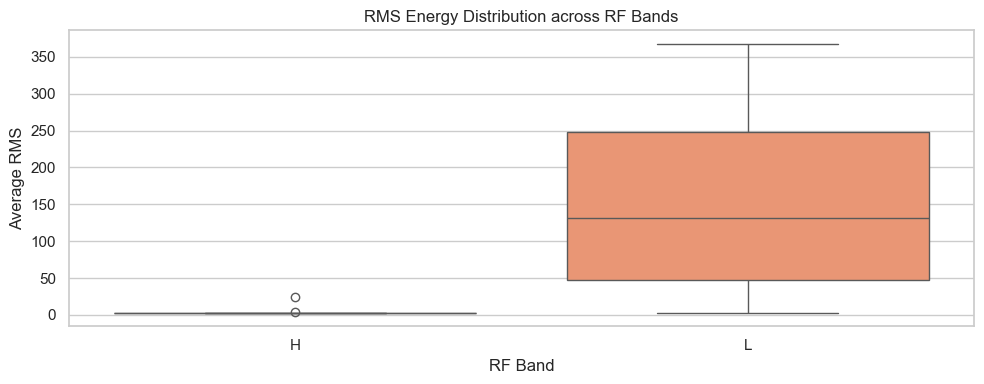

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Query engineered dataframe for visualization
df_viz = con.execute("""
    SELECT band, code, AVG(rms) as avg_rms, AVG(spec_e_lo_norm) as lo, AVG(spec_e_mid_norm) as mid, AVG(spec_e_hi_norm) as hi
    FROM rf_features
    GROUP BY band, code
""").df()

# Dynamic Plot: Band Comparison
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_viz, x='band', y='avg_rms', palette='Set2')
plt.title("RMS Energy Distribution across RF Bands")
plt.xlabel("RF Band")
plt.ylabel("Average RMS")
plt.tight_layout()
plt.show()

### 4.2: EXPORT ENGINEERED DATASET
Cell 4.2: Save Final Engineered Table to Parquet


In [15]:
ENGINEERED_OUTPUT_FILE = os.path.join(PROCESSED_DIR, "feat_engineered.parquet")

# Export DuckDB table with lag/rolling features to parquet
con.execute(f"""
    COPY rf_features_engineered 
    TO '{ENGINEERED_OUTPUT_FILE}' (FORMAT PARQUET, COMPRESSION 'SNAPPY');
""")

print(f"✅ Final engineered features exported to: {ENGINEERED_OUTPUT_FILE}")

✅ Final engineered features exported to: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\feat_engineered.parquet


## Bước 5


### 5.1: MANIFEST GENERATION & VERIFICATION
Cell 5.1: Create Standardized manifest.json for Delivery


In [16]:
# 5.1: Summary and checksum verification prior to handoff
# (OFFICIAL manifest.json is created solely in the Test Case below to avoid mismatched contents)
import hashlib

def calculate_md5(file_path):
    md5_hash = hashlib.md5()
    with open(file_path, "rb") as f:
        for byte_block in iter(lambda: f.read(4096), b""):
            md5_hash.update(byte_block)
    return md5_hash.hexdigest()

print("Data summary prior to handoff:")
print(f" - Main file (Step 2)   : {OUTPUT_FILE}")
print(f"   + Size               : {os.path.getsize(OUTPUT_FILE) / (1024 * 1024):.2f} MB")
print(f"   + MD5                : {calculate_md5(OUTPUT_FILE)}")
if "ENGINEERED_OUTPUT_FILE" in dir() and os.path.exists(ENGINEERED_OUTPUT_FILE):
    print(f" - Engineered features file (Step 4.2): {ENGINEERED_OUTPUT_FILE}")
print(f" - Total rows           : {len(df_clean):,}")
print(f" - Frequency bands      : {df_clean['band'].unique().tolist()}")
print(f" - Unique code count    : {df_clean['code'].nunique()}")
print(" - Drone/background ratio:")
print(df_clean["drone"].value_counts(normalize=True).round(3))

Data summary prior to handoff:
 - Main file (Step 2)   : d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf.parquet
   + Size               : 20.73 MB
   + MD5                : 045989747ee22662c3113e67deb32c57
 - Engineered features file (Step 4.2): d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\feat_engineered.parquet
 - Total rows           : 226,546
 - Frequency bands      : ['H', 'L']
 - Unique code count    : 10
 - Drone/background ratio:
drone
1    0.819
0    0.181
Name: proportion, dtype: float64


## Test case của Notebook_A (chạy trước khi bàn giao)

Mỗi assert là một điều kiện phải đúng; nếu sai, sửa bước tương ứng rồi chạy lại. Sau khi qua hết, ô cuối tạo `manifest.json` để Sinh viên B kiểm tra.

In [17]:
import hashlib
import json
from pathlib import Path

print("=== RUNNING HANDOFF TEST SUITE ===")

# 1. Use df_clean directly (normalized + labeled table from Step 2), DO NOT re-read non-existent SQL table
feat = df_clean.copy()

# 2. Mandatory conditions
assert len(feat) >= 30000, f"Only {len(feat)} rows found, minimum 30,000 required."
print(f"[OK] Test 1: {len(feat):,} rows >= 30,000.")

assert feat["drone"].notna().sum() > 0.8 * len(feat), "Too many missing values in 'drone' label."
print("[OK] Test 2: 'drone' label completion rate sufficient (>80%).")

key = ["code", "seg", "win", "band"]
before = len(feat)
feat = feat.drop_duplicates(subset=key).reset_index(drop=True)
print(f"[OK] Test 3: Duplicates removed based on key {key} (removed {before - len(feat)} rows, remaining {len(feat):,}).")

lead_cols = [c for c in feat.columns if c.startswith("y_")]
assert len(lead_cols) == 0, f"Potential data leakage columns detected: {lead_cols}"
print("[OK] Test 4: No future data leakage columns detected.")

# 3. Overwrite OUTPUT_FILE with the deduplicated version (if Test 3 removed any rows)
feat.to_parquet(OUTPUT_FILE, index=False, compression="snappy")

# 4. Create manifest.json for handoff to Notebook_B (using exact field names expected by Notebook_B: md5, rows, cols, time_min, time_max)
md5_hash = hashlib.md5(open(OUTPUT_FILE, "rb").read()).hexdigest()
manifest_data = {
    "project": "DroneRF_Project",
    "step": "Notebook_A_Preprocessing",
    "status": "PASSED_ALL_TESTS",
    "output_file": OUTPUT_FILE,
    "md5": md5_hash,
    "rows": len(feat),
    "cols": list(feat.columns),
    "time_min": "n/a (DroneRF has no time axis, unit is 2ms window)",
    "time_max": "n/a (DroneRF has no time axis, unit is 2ms window)",
    "target_distribution": feat["drone"].value_counts().to_dict(),
}

Path(MANIFEST_FILE).parent.mkdir(parents=True, exist_ok=True)
with open(MANIFEST_FILE, "w", encoding="utf-8") as f:
    json.dump(manifest_data, f, indent=4, ensure_ascii=False)

print("\n" + "=" * 50)
print("-> TEST SUITE PASSED 100%!")
print(f"-> HANDOFF FILE CREATED: {MANIFEST_FILE}")
print(f"-> HANDOFF PARQUET FILE: {OUTPUT_FILE}")
print("=" * 50)

=== RUNNING HANDOFF TEST SUITE ===
[OK] Test 1: 226,546 rows >= 30,000.
[OK] Test 2: 'drone' label completion rate sufficient (>80%).
[OK] Test 3: Duplicates removed based on key ['code', 'seg', 'win', 'band'] (removed 0 rows, remaining 226,546).
[OK] Test 4: No future data leakage columns detected.

-> TEST SUITE PASSED 100%!
-> HANDOFF FILE CREATED: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\manifest.json
-> HANDOFF PARQUET FILE: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\data\processed\dronerf.parquet


C:\Users\PV\AppData\Local\Temp\ipykernel_16464\2776637131.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='drone', y=col, palette=['#4C72B0', '#DD8452'], ax=ax, width=0.4)
C:\Users\PV\AppData\Local\Temp\ipykernel_16464\2776637131.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No Drone (0)', 'Drone (1)'])
C:\Users\PV\AppData\Local\Temp\ipykernel_16464\2776637131.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='drone', y=col, palette=['#4C72B0', '#DD8452'], ax=ax, width=0.4)
C:\Users\PV\AppData\Local\Temp\ipykernel_16464\2776637131.py:20: 

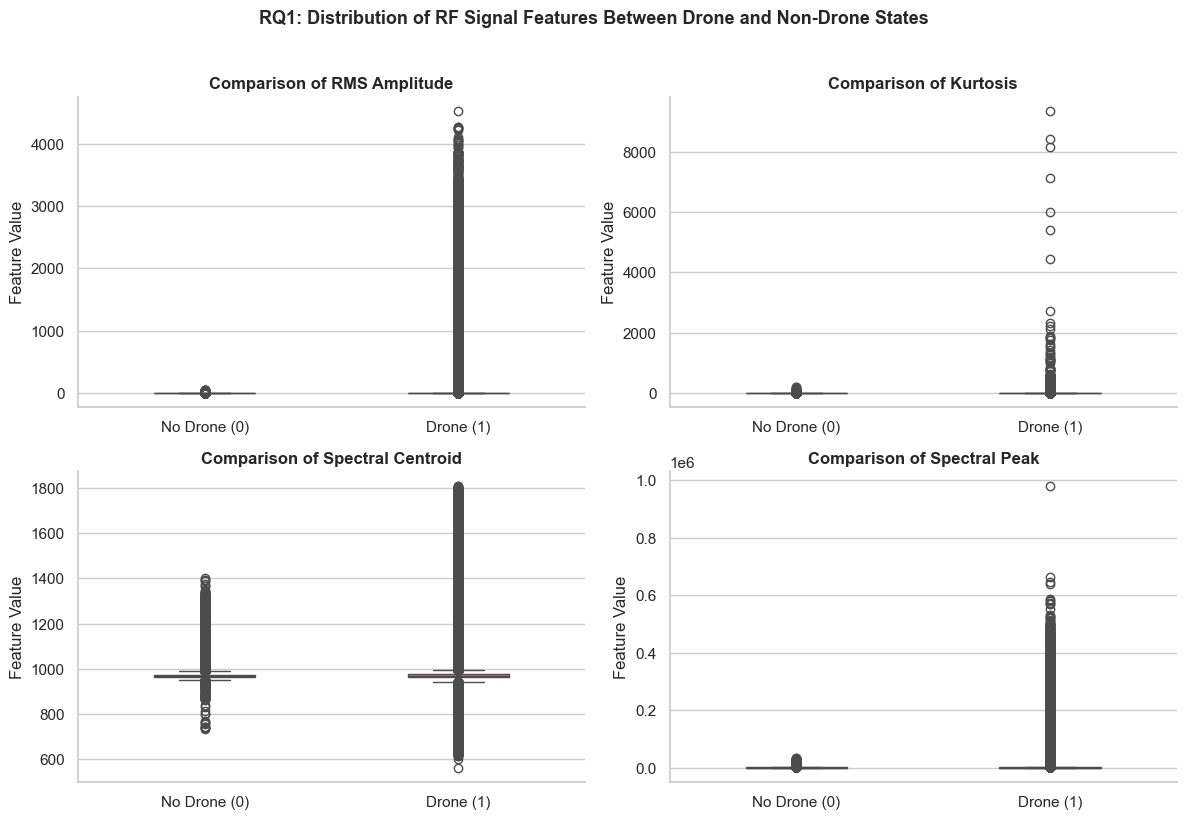

[OK] Exported successfully: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\fig_rq1_feature_distribution.png


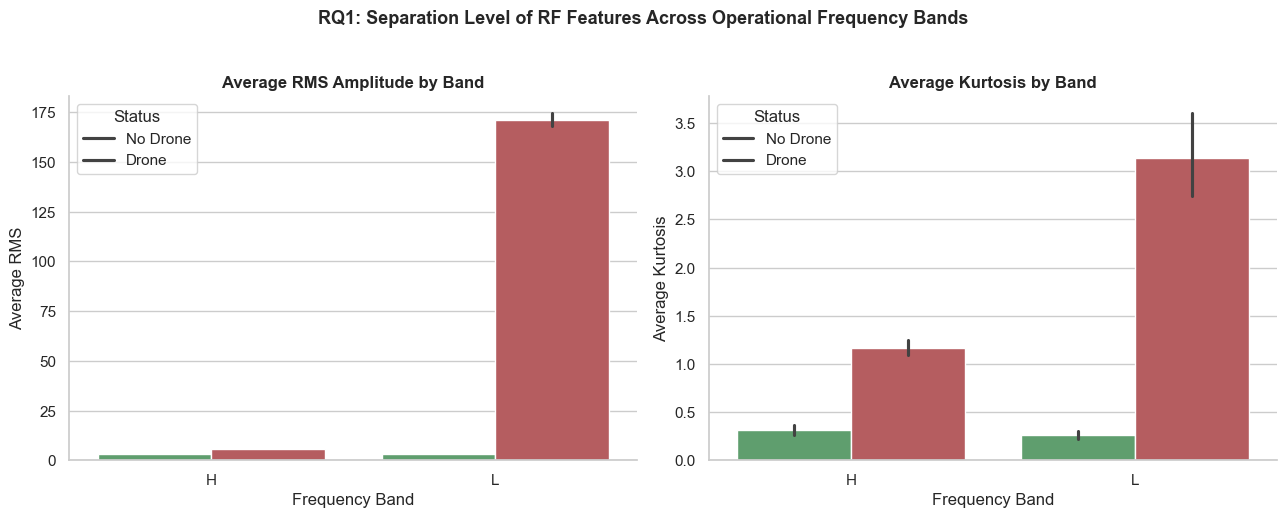

[OK] Exported successfully: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\fig_rq1_band_comparison.png


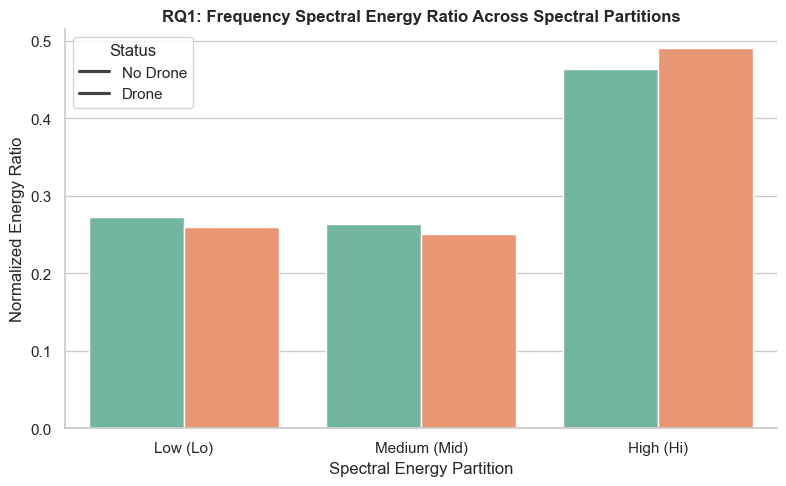

[OK] Exported successfully: d:\FPT_K20_AI\SEMESTER_3\ADY201m\DroneRF_Project\Project_1D\report\fig_rq1_energy_spectrum.png


In [18]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set standard chart theme for reports
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

# -------------------------------------------------------------
# Figure 1: fig_rq1_feature_distribution.png (Key feature boxplots)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
key_features = ['rms', 'kurt', 'spec_centroid', 'spec_max']
feature_titles = ['RMS Amplitude', 'Kurtosis', 'Spectral Centroid', 'Spectral Peak']

for idx, col in enumerate(key_features):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(data=df_clean, x='drone', y=col, palette=['#4C72B0', '#DD8452'], ax=ax, width=0.4)
    ax.set_xticklabels(['No Drone (0)', 'Drone (1)'])
    ax.set_title(f"Comparison of {feature_titles[idx]}", fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Feature Value")
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle("RQ1: Distribution of RF Signal Features Between Drone and Non-Drone States", 
             fontsize=13, fontweight='bold', y=1.02)

fig1_path = os.path.join(REPORT_DIR, "fig_rq1_feature_distribution.png")
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[OK] Exported successfully: {fig1_path}")

# -------------------------------------------------------------
# Figure 2: fig_rq1_band_comparison.png (Comparison across frequency bands)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=df_clean, x='band', y='rms', hue='drone', palette=['#55A868', '#C44E52'], ax=axes[0])
axes[0].set_title("Average RMS Amplitude by Band", fontweight='bold')
axes[0].set_xlabel("Frequency Band")
axes[0].set_ylabel("Average RMS")
axes[0].legend(title="Status", labels=['No Drone', 'Drone'])
axes[0].spines[['top', 'right']].set_visible(False)

sns.barplot(data=df_clean, x='band', y='kurt', hue='drone', palette=['#55A868', '#C44E52'], ax=axes[1])
axes[1].set_title("Average Kurtosis by Band", fontweight='bold')
axes[1].set_xlabel("Frequency Band")
axes[1].set_ylabel("Average Kurtosis")
axes[1].legend(title="Status", labels=['No Drone', 'Drone'])
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle("RQ1: Separation Level of RF Features Across Operational Frequency Bands", fontsize=13, fontweight='bold', y=1.03)

fig2_path = os.path.join(REPORT_DIR, "fig_rq1_band_comparison.png")
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[OK] Exported successfully: {fig2_path}")

# -------------------------------------------------------------
# Figure 3: fig_rq1_energy_spectrum.png (Spectral energy ratio)
# -------------------------------------------------------------
e_df = df_clean.groupby('drone')[['spec_e_lo_norm', 'spec_e_mid_norm', 'spec_e_hi_norm']].mean().reset_index()
e_df_melted = pd.melt(e_df, id_vars=['drone'], var_name='energy_band', value_name='ratio')
e_df_melted['energy_band'] = e_df_melted['energy_band'].map({
    'spec_e_lo_norm': 'Low (Lo)',
    'spec_e_mid_norm': 'Medium (Mid)',
    'spec_e_hi_norm': 'High (Hi)'
})

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=e_df_melted, x='energy_band', y='ratio', hue='drone', palette='Set2', ax=ax)
ax.set_title("RQ1: Frequency Spectral Energy Ratio Across Spectral Partitions", fontsize=12, fontweight='bold')
ax.set_xlabel("Spectral Energy Partition")
ax.set_ylabel("Normalized Energy Ratio")
ax.legend(title="Status", labels=['No Drone', 'Drone'])
ax.spines[['top', 'right']].set_visible(False)

fig3_path = os.path.join(REPORT_DIR, "fig_rq1_energy_spectrum.png")
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[OK] Exported successfully: {fig3_path}")

## Lỗi thường gặp và cách xử lý (đọc khi thấy chữ đỏ)

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| ModuleNotFoundError | chưa cài thư viện hoặc chọn sai interpreter | chạy lại pip install ở Bước 0; Ctrl+Shift+P chọn interpreter .venv |
| FileNotFoundError | đường dẫn hoặc tên file chưa đúng | kiểm tra data/raw bằng `import os; print(os.listdir('data/raw'))` |
| KeyError: 'ten_cot' | tên cột thật khác tên trong code | in `df.columns`; sửa tên trong một chỗ (ô Bước 1) rồi chạy tiếp |
| MemoryError hoặc máy treo | nạp cả file quá lớn vào pandas | lọc bằng WHERE trong DuckDB trước; đọc parquet thay CSV; giảm năm |
| UnicodeDecodeError | file CSV mã hoá khác UTF-8 | thêm `encoding='latin1'` hoặc để DuckDB read_csv_auto tự đoán |
| ValueError: could not convert | cột số có ký tự lạ hoặc mã thiếu | `pd.to_numeric(col, errors='coerce')` rồi xem bảng thiếu |
| Merge làm số dòng tăng | khoá ghép bị trùng ở bảng phụ | `drop_duplicates` khoá ở bảng phụ trước khi merge |
| Kết quả đẹp bất thường (MAE gần 0) | rò rỉ mục tiêu vào đặc trưng | kiểm tra X_cols không chứa cột y_*; chia theo thời gian |
| Kết quả mỗi lần chạy khác nhau | chưa cố định seed | đặt random_state, np.random.seed(42) |

Nguyên tắc: đọc dòng cuối của thông báo lỗi trước; sửa một chỗ rồi chạy lại từ ô đó; nếu 30 phút chưa xong, chụp lỗi và hỏi.

## Checklist trước khi báo cáo (đánh dấu [x] khi có file bằng chứng)

- [ ] requirements.txt, README.md, .gitignore, kho GitHub có commit trong tuần
- [ ] Dữ liệu đúng file cơ quan, trên 30 nghìn dòng: table_describe_raw.csv, profile.html
- [ ] EDA: table_describe_numeric.csv, table_describe_categorical.csv, table_eda_notes.csv, table_missing.csv, table_columns.csv, table_target_by_unit.csv, table_target_by_period.csv
- [ ] Làm sạch: table_cleaning_log.csv; ghép nguồn thứ hai khớp trên 90%
- [ ] SQL: sql/queries.sql, table_q1..q4.csv; RQ1: table_rq1a_period.csv, table_rq1b_corr.csv, table_rq1c_units.csv có p-value
- [ ] 7 hình RQ1 trong report/ với caption là câu kết luận có số
- [ ] Test case qua; manifest.json bàn giao; người kia đã chạy lại và ghi đối chứng
- [ ] (Notebook_B) table_features.csv, table_rq2.csv, 4 hình RQ2, table_tuning.csv, table_rq3_*.csv, table_shap.csv, table_diagnosis.csv, params_best.json
- [ ] Audit Log cá nhân có đủ prompt của tuần
- [ ] Báo cáo năm mục đã dán vào kênh nhóm trước 12:00 thứ Ba hoặc thứ Sáu


## Mẫu báo cáo tiến độ (slot 3 thứ Ba và thứ Sáu, 7:00 đến 9:15)

Dán vào kênh nhóm trước 12:00 ngày báo cáo, mỗi người một phần. Năm mục, mỗi mục hai đến ba dòng:

1. **Đã xong** từ lần trước: tên file, số dòng, số bảng, số hình (ví dụ: `feat.parquet` 138.204 dòng; 4 bảng RQ1; 7 hình).
2. **Con số chính mới có**: ví dụ MAE naive 6,8; MAE LightGBM 4,7 (5 seed, sd 0,1).
3. **Vướng mắc và đã thử gì**: lỗi cụ thể, ảnh chụp, hai cách đã thử.
4. **Sẽ làm đến lần sau, ai làm**: theo Bảng 13 của đề cương.
5. **Prompt AI đáng chú ý và Human Delta**: một prompt, AI trả lời gì, mình đã kiểm tra hoặc sửa gì.

**Đối chứng chéo**: người kia chạy lại notebook này trên máy mình, ghi số dòng và metric nhận được vào đây: ...............................